# NLP - Suç Tipi Sınıflandırma

Bu projede Los Angeles suç kayıtlarındaki mekan ve silah açıklamalarından suçun türünü tahmin edeceğiz.

In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.max_columns',100)

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('la_crime.csv',usecols=['Crm Cd Desc','Premis Desc','Weapon Desc'])

In [3]:
df.head()

,Crm Cd Desc,Premis Desc,Weapon Desc
0,THEFT OF IDENTITY,SINGLE FAMILY DWELLING,NaN
1,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",SIDEWALK,KNIFE WITH BLADE 6INCHES OR LESS
2,THEFT OF IDENTITY,SINGLE FAMILY DWELLING,NaN
3,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,STREET,NaN
4,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),ALLEY,NaN


In [4]:
df.isnull().sum()

Crm Cd Desc         0
Premis Desc       588
Weapon Desc    677678
dtype: int64

In [5]:
df['Weapon Desc']=df['Weapon Desc'].fillna('NO WEAPON')
df=df.dropna(subset=['Crm Cd Desc','Premis Desc'])

Çok sayıda suç türü olduğu için en sık görülen 10 türü alıyoruz.

In [6]:
en_sik=df['Crm Cd Desc'].value_counts().head(10).index
df=df[df['Crm Cd Desc'].isin(en_sik)]

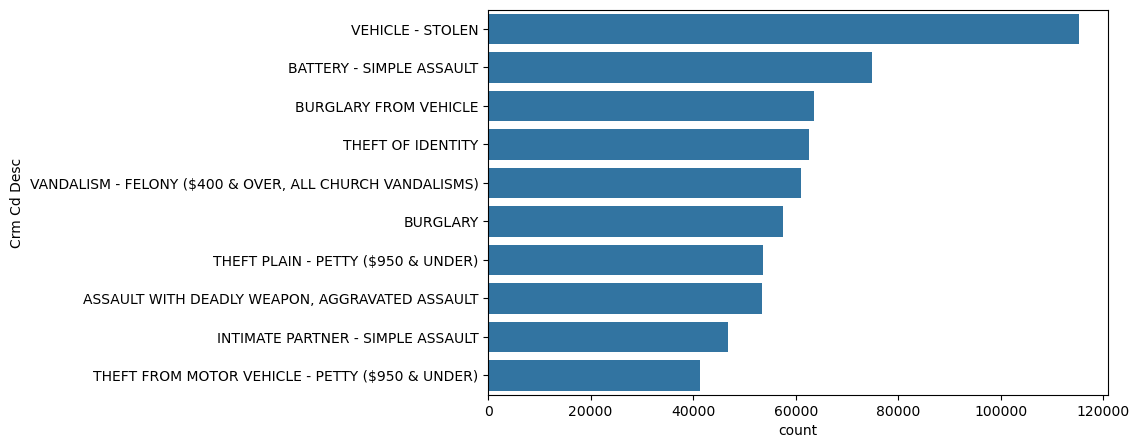

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(y=df['Crm Cd Desc'],order=df['Crm Cd Desc'].value_counts().index);

In [8]:
df=df.sample(n=min(50000,len(df)),random_state=42)

In [9]:
df['metin']=df['Premis Desc']+' '+df['Weapon Desc']
df[['metin','Crm Cd Desc']].head()

,metin,Crm Cd Desc
42394,SINGLE FAMILY DWELLING NO WEAPON,THEFT OF IDENTITY
652284,STREET NO WEAPON,VEHICLE - STOLEN
775657,SINGLE FAMILY DWELLING NO WEAPON,THEFT OF IDENTITY
523789,STREET NO WEAPON,VEHICLE - STOLEN
422864,STREET SEMI-AUTOMATIC PISTOL,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT"


In [10]:
x=df['metin']
y=df['Crm Cd Desc']

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.15,random_state=42)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [13]:
nb=make_pipeline(TfidfVectorizer(),MultinomialNB())
nb.fit(x_train,y_train)
nbtahmin=nb.predict(x_test)

In [14]:
accuracy_score(y_test,nbtahmin)

0.5614666666666667

In [15]:
print(classification_report(y_test,nbtahmin))

                                                         precision    recall  f1-score   support

         ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT       0.86      0.71      0.78       619
                               BATTERY - SIMPLE ASSAULT       0.74      0.62      0.68       922
                                               BURGLARY       0.47      0.41      0.43       694
                                  BURGLARY FROM VEHICLE       0.34      0.19      0.24       745
                      INTIMATE PARTNER - SIMPLE ASSAULT       0.56      0.75      0.64       550
        THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)       0.00      0.00      0.00       491
                                      THEFT OF IDENTITY       0.50      0.87      0.63       721
                     THEFT PLAIN - PETTY ($950 & UNDER)       0.50      0.38      0.43       645
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)       0.74      0.30      0.42       766
                             

In [16]:
L=make_pipeline(TfidfVectorizer(),LogisticRegression(max_iter=1000))
L.fit(x_train,y_train)
Ltahmin=L.predict(x_test)

In [17]:
accuracy_score(y_test,Ltahmin)

0.5702666666666667

In [18]:
print(classification_report(y_test,Ltahmin))

                                                         precision    recall  f1-score   support

         ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT       0.83      0.80      0.81       619
                               BATTERY - SIMPLE ASSAULT       0.73      0.64      0.68       922
                                               BURGLARY       0.47      0.40      0.43       694
                                  BURGLARY FROM VEHICLE       0.36      0.17      0.23       745
                      INTIMATE PARTNER - SIMPLE ASSAULT       0.56      0.75      0.64       550
        THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)       0.00      0.00      0.00       491
                                      THEFT OF IDENTITY       0.49      0.89      0.64       721
                     THEFT PLAIN - PETTY ($950 & UNDER)       0.54      0.38      0.44       645
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)       0.81      0.30      0.44       766
                             

In [19]:
L.predict(['STREET HANDGUN'])

array(['ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT'], dtype=object)

In [20]:
import pickle
pickle.dump(L,open('suc_nlp_model.pkl','wb'))